# 11a v2: Tourism Monthly, desempenho em dados limpos (Fase 4a)

Terceira base, com o protocolo único v2 (`src/pipeline_v2.py`), idêntico ao do M4 e do Car Parts exceto pelo horizonte: **H = 24** (benchmark original do Tourism; M4 e Car Parts usam 18).

- Amostra: 200 séries (sorteio SEED=42 na ordem do arquivo), janelas por `linspace(24, n − 24, 3)`.
- Todos os modelos, inclusive o SARIMA automático (ordem escolhida em cada janela, só com o treino).
- Previsões registradas **antes** desta execução: `results/v2/PREVISOES_tourism.md` (commit "Previsões registradas antes da execução do Tourism"). Nesta parte só a **H4** pode ser avaliada; H1 a H3 dependem da explicabilidade (4c).

In [1]:
import sys, json, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

_root = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in (_root, *_root.parents) if (c / 'src' / 'pipeline_v2.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src import pipeline_v2 as pv

V2 = PROJECT_ROOT / 'results' / 'v2'
DIR = V2 / 'tm' / 'limpo'
DATA = PROJECT_ROOT / 'data' / 'raw'
NOMES = {'holt_winters': 'Holt-Winters', 'persistence': 'Persistência', 'ses': 'SES', 'sarima_auto': 'SARIMA automático',
         'gbt': 'Gradient Boosting', 'sarima_heuristic': 'SARIMA heurístico', 'random_forest': 'Random Forest',
         'seasonal_naive': 'Sazonal ingênuo', 'svr': 'SVR', 'mean': 'Média histórica'}
pd.set_option('display.width', 260)

def carregar(pasta, prefixo):
    return pd.concat([pd.read_csv(f) for f in sorted(pasta.glob(f'{prefixo}_limpo_*_by_window.csv'))], ignore_index=True)

ids_tm, ser_tm = pv.amostra_tsf(pv.load_tsf(DATA / 'tourism_monthly_dataset.tsf', 'latin-1'), 200)
ids_m4, ser_m4 = pv.load_m4_piloto(DATA, 200)
ser_cp = pv.load_tsf(DATA / 'car_parts' / 'car_parts_dataset_without_missing_values.tsf')

tm = pv.adicionar_mase(carregar(DIR, 'tm'), dict(zip(ids_tm, ser_tm)))
m4 = pv.adicionar_mase(carregar(V2 / 'm4' / 'limpo', 'm4'), dict(zip(ids_m4, ser_m4)))
cp = pv.adicionar_mase(carregar(V2 / 'cp' / 'limpo', 'cp'), ser_cp)
MODELOS = [m for m in pv.MODELOS if m in tm.model.unique()]
print(f'Tourism: {len(tm):,} janelas | {tm.unique_id.nunique()} séries | modelos: {len(MODELOS)} | H=24')
assert set(tm.unique_id) == set(ids_tm)
meta = json.loads(next(DIR.glob('*.meta.json')).read_text(encoding='utf-8'))
print('pipeline_sha256 =', meta['pipeline_sha256'][:16], '| dados:', [(d['arquivo'], d['sha256'][:12]) for d in meta['dados']])

Tourism: 6,000 janelas | 200 séries | modelos: 10 | H=24
pipeline_sha256 = bbe78767e39584b6 | dados: [('tourism_monthly_dataset.tsf', 'fba16c20b9c4')]


## 1. Status, fallback por janela e previsões explosivas

In [2]:
taxas = (100 * pv.taxas_status(tm)).round(1); taxas.index = [NOMES[m] for m in taxas.index]
print('Status (% das janelas):'); print(taxas.to_string())
fbj = (100 * pv.taxas_fallback_por_janela(tm)).round(1); fbj.index = [NOMES[m] for m in fbj.index]
fbj.columns = [f'janela {int(c)}' for c in fbj.columns]
print('\nFallback por janela (% das séries):'); print(fbj.to_string())
mot = tm[tm.status.isin([pv.FB_SNAIVE, pv.FB_MEAN]) & (tm['info'].fillna('') != '')]
if len(mot):
    print('\nMotivos:', mot.assign(m=mot['info'].map(lambda s: json.loads(s).get('motivo', 'n/d'))).groupby(['model', 'm']).size().to_dict())
ex = tm.assign(e=pv.flag_explosiva(tm)).groupby('model')['e'].agg(['sum', 'mean'])
print('Explosivas (sinalizadas, status OK):', {NOMES[m]: f'{int(r["sum"])} ({100*r["mean"]:.1f}%)' for m, r in ex.iterrows() if r['sum'] > 0})
taxas.to_csv(DIR / 'tm_limpo_taxas_status.csv'); fbj.to_csv(DIR / 'tm_limpo_fallback_por_janela.csv')

Status (% das janelas):
status                OK  FALLBACK_SNAIVE  FALLBACK_MEAN  ERRO  SEM_JANELA
Gradient Boosting  100.0              0.0            0.0   0.0         0.0
Holt-Winters       100.0              0.0            0.0   0.0         0.0
Média histórica    100.0              0.0            0.0   0.0         0.0
Persistência       100.0              0.0            0.0   0.0         0.0
Random Forest      100.0              0.0            0.0   0.0         0.0
SARIMA automático  100.0              0.0            0.0   0.0         0.0
SARIMA heurístico   66.7             33.3            0.0   0.0         0.0
Sazonal ingênuo    100.0              0.0            0.0   0.0         0.0
SES                100.0              0.0            0.0   0.0         0.0
SVR                100.0              0.0            0.0   0.0         0.0

Fallback por janela (% das séries):
                   janela 1  janela 2  janela 3
Gradient Boosting       0.0       0.0       0.0
Holt-Winters      

## 2. Tabela de desempenho v2 do Tourism: ranking por MAPE e por MAE (e MASE)
SVR e SARIMA (e os demais) com e sem as janelas de fallback; SARIMA também sem as janelas explosivas.

In [3]:
bs = pv.agregar_por_serie(tm)
r = pv.resumo_modelos(bs)
r_sf = pv.resumo_modelos(pv.agregar_por_serie(tm, incluir_fallback=False))
r_se = pv.resumo_modelos(pv.agregar_por_serie(tm, excluir_explosivas=True))
tab = pd.DataFrame({
    'Família': r['familia'],
    'MAPE (%)': r['mape'], 'Rank MAPE': r['mape'].rank(method='min').astype(int),
    'MAE': r['mae'], 'Rank MAE': r['mae'].rank(method='min').astype(int),
    'MASE': r['mase'], 'Rank MASE': r['mase'].rank(method='min').astype(int),
    'R²': r['r2'],
    'MAPE sem fallback': r_sf['mape'], 'MAE sem fallback': r_sf['mae'],
    'MAPE sem explosivas': r_se['mape'],
    'Fallback (% jan.)': 100 * pv.taxas_status(tm)[[pv.FB_SNAIVE, pv.FB_MEAN]].sum(axis=1),
    'Explosivas (% jan.)': 100 * tm.assign(e=pv.flag_explosiva(tm)).groupby('model')['e'].mean(),
}).sort_values('Rank MAPE').round(3)
tab.index = [NOMES[m] for m in tab.index]
print('Tourism Monthly, protocolo v2: 200 séries, H=24, 3 origens')
print(tab.to_string())
tab.to_csv(DIR / 'tabela_desempenho_v2_tm.csv')

Tourism Monthly, protocolo v2: 200 séries, H=24, 3 origens
                                  Família  MAPE (%)  Rank MAPE      MAE  Rank MAE   MASE  Rank MASE     R²  MAPE sem fallback  MAE sem fallback  MAPE sem explosivas  Fallback (% jan.)  Explosivas (% jan.)
Holt-Winters       Suavização exponencial    21.614          1  365.000         4  1.349          1  0.365             21.614           365.000               21.614              0.000                0.000
Sazonal ingênuo                  Baseline    23.357          2  354.542         3  1.395          3  0.256             23.357           354.542               23.357              0.000                0.000
SARIMA automático                   ARIMA    23.411          3  329.132         2  1.462          4  0.254             23.411           329.132               23.157              0.000                1.333
SARIMA heurístico                   ARIMA    23.764          4  315.104         1  1.360          2  0.339             22

## 3. Comparação de ranks com M4 e Car Parts (bootstrap pareado por série dentro de cada base)
Mesma métrica nas três bases: **MAE** e **MASE** (o MAPE também é comparado entre M4 e Tourism, que não têm zeros; no Car Parts ele é indefinido em 16% das janelas). Ranks sobre os 10 modelos comuns.

In [4]:
BASES = {'M4': m4, 'Car Parts': cp, 'Tourism': tm}
COMUNS = [m for m in MODELOS if all(m in d.model.unique() for d in BASES.values())]
res, boots = {}, {}
for met in ['mape', 'mae', 'mase']:
    for b, d in BASES.items():
        if met == 'mape' and b == 'Car Parts':
            continue
        res[(met, b)], boots[(met, b)] = pv.bootstrap_ranks(pv.agregar_por_serie(d), COMUNS, met, n=2000)
linhas = []
for m in COMUNS:
    lin = {'modelo': NOMES[m], 'família': pv.FAMILIA[m]}
    for (met, b), t in res.items():
        lin[f'{met.upper()} {b}'] = f"{int(t.loc[m, 'rank'])} [{t.loc[m, 'rank_ic_inf']:.0f}; {t.loc[m, 'rank_ic_sup']:.0f}]"
    linhas.append(lin)
comp = pd.DataFrame(linhas).set_index('modelo')
print(comp.to_string())
comp.to_csv(DIR / 'ranks_tres_bases_tm.csv')

def rho_ic(a, b, met):
    ta, tb = res[(met, a)], res[(met, b)]
    rho = spearmanr(ta['rank'], tb['rank'])[0]
    ra, rb = boots[(met, a)].rank(axis=1).values, boots[(met, b)].rank(axis=1).values
    rng = np.random.default_rng(pv.SEED)
    rr = [spearmanr(ra[i], rb[j])[0] for i, j in zip(rng.integers(0, 2000, 2000), rng.integers(0, 2000, 2000))]
    return rho, np.percentile(rr, 2.5), np.percentile(rr, 97.5)
print('\nSpearman entre os rankings dos modelos [IC 95%]:')
for met in ['mae', 'mase']:
    for a, b in [('Tourism', 'M4'), ('Tourism', 'Car Parts'), ('M4', 'Car Parts')]:
        print(f'  {met.upper():<4} {a} x {b:<10}: {rho_ic(a, b, met)[0]:+.3f} [{rho_ic(a, b, met)[1]:+.3f}; {rho_ic(a, b, met)[2]:+.3f}]')
print(f"  MAPE Tourism x M4        : {rho_ic('Tourism', 'M4', 'mape')[0]:+.3f} [{rho_ic('Tourism', 'M4', 'mape')[1]:+.3f}; {rho_ic('Tourism', 'M4', 'mape')[2]:+.3f}]")

                                  família      MAPE M4 MAPE Tourism       MAE M4 MAE Car Parts MAE Tourism      MASE M4 MASE Car Parts MASE Tourism
modelo                                                                                                                                             
Persistência                     Baseline     6 [3; 8]     9 [9; 9]     5 [2; 7]      1 [1; 1]  10 [9; 10]     4 [1; 8]       1 [1; 1]     9 [9; 9]
Média histórica                  Baseline  10 [10; 10]  10 [10; 10]  10 [10; 10]      7 [7; 8]   9 [9; 10]  10 [10; 10]       5 [4; 5]  10 [10; 10]
Sazonal ingênuo                  Baseline     9 [8; 9]     2 [1; 5]     9 [7; 9]      5 [3; 6]    3 [1; 5]     8 [6; 9]       6 [6; 7]     3 [1; 4]
SES                Suavização exponencial     4 [3; 7]     8 [8; 8]     4 [1; 7]      4 [4; 6]    8 [8; 8]     3 [1; 7]       3 [3; 4]     8 [8; 8]
Holt-Winters       Suavização exponencial     1 [1; 3]     1 [1; 2]     3 [1; 7]   10 [10; 10]    4 [1; 6]     2

## 4. H4: hierarquia entre famílias (avaliação conforme o critério registrado)
Critério de `PREVISOES_tourism.md`: métrica MASE com fallback; rank da família = posição do seu melhor modelo; **confirmou** se a ordem do Tourism difere da do M4 e da do Car Parts e, em cada comparação, pelo menos uma família tem IC do rank sem sobreposição; **parcial** se difere nas estimativas pontuais mas a separação de IC ocorre em no máximo uma comparação; **não confirmou** se a ordem é idêntica à de pelo menos uma base.

In [5]:
def familias(met, base):
    t, boot = res[(met, base)], boots[(met, base)]
    fam = pd.Series(pv.FAMILIA)[COMUNS]
    pont = t.groupby(fam.values)['mediana'].min().rank(method='min').astype(int)
    rb = boot.T.groupby(fam.values).min().T.rank(axis=1, method='min')
    return pd.DataFrame({'rank': pont, 'ic_inf': rb.quantile(0.025), 'ic_sup': rb.quantile(0.975)})

def avaliar_h4(met):
    f = {b: familias(met, b) for b in BASES}
    ordem = {b: tuple(f[b].sort_values(['rank']).index) for b in BASES}
    difere = {b: ordem['Tourism'] != ordem[b] for b in ['M4', 'Car Parts']}
    separa = {}
    for b in ['M4', 'Car Parts']:
        separa[b] = [fam for fam in f['Tourism'].index
                     if f['Tourism'].loc[fam, 'ic_inf'] > f[b].loc[fam, 'ic_sup'] or f['Tourism'].loc[fam, 'ic_sup'] < f[b].loc[fam, 'ic_inf']]
    if not all(difere.values()):
        status = 'não confirmou'
    elif all(len(v) > 0 for v in separa.values()):
        status = 'confirmou'
    else:
        status = 'confirmou parcialmente'
    tab = pd.concat({b: f[b].apply(lambda r: f"{int(r['rank'])} [{r.ic_inf:.0f}; {r.ic_sup:.0f}]", axis=1) for b in BASES}, axis=1)
    return status, tab, ordem, difere, separa

for met in ['mase', 'mae']:
    status, tab_f, ordem, difere, separa = avaliar_h4(met)
    rot = 'PRINCIPAL (critério registrado)' if met == 'mase' else 'secundária, só reportada'
    print(f'=== {met.upper()} | {rot} ===')
    print(tab_f.to_string())
    for b in BASES:
        print(f'  ordem {b:<9}: ' + ' > '.join(ordem[b]))
    print(f'  difere do M4: {difere["M4"]} | difere do Car Parts: {difere["Car Parts"]}')
    print(f'  famílias com IC separado: vs M4 = {separa["M4"]} | vs Car Parts = {separa["Car Parts"]}')
    print(f'  H4 ({met.upper()}): {status.upper()}'); print()
    tab_f.to_csv(DIR / f'familias_tres_bases_{met}_tm.csv')
    if met == 'mase':
        H4 = {'hipotese': 'H4', 'previsao': 'a hierarquia entre famílias difere da do M4 e da do Car Parts',
              'status': status, 'evidencia': f"ordem TM: {' > '.join(ordem['Tourism'])}; M4: {' > '.join(ordem['M4'])}; "
                                             f"CP: {' > '.join(ordem['Car Parts'])}; IC separado vs M4: {separa['M4']}, vs CP: {separa['Car Parts']}",
              'parte': '4a', 'fonte': 'tm/limpo/familias_tres_bases_mase_tm.csv'}

=== MASE | PRINCIPAL (critério registrado) ===
                              M4 Car Parts   Tourism
ARIMA                   4 [2; 4]  4 [4; 4]  2 [1; 3]
Baseline                3 [1; 4]  1 [1; 1]  3 [1; 3]
ML                      1 [1; 4]  2 [2; 2]  4 [4; 4]
Suavização exponencial  2 [1; 3]  3 [3; 3]  1 [1; 3]
  ordem M4       : ML > Suavização exponencial > Baseline > ARIMA
  ordem Car Parts: Baseline > ML > Suavização exponencial > ARIMA
  ordem Tourism  : Suavização exponencial > ARIMA > Baseline > ML
  difere do M4: True | difere do Car Parts: True
  famílias com IC separado: vs M4 = [] | vs Car Parts = ['ARIMA', 'ML']
  H4 (MASE): CONFIRMOU PARCIALMENTE

=== MAE | secundária, só reportada ===
                              M4 Car Parts   Tourism
ARIMA                   4 [1; 4]  4 [4; 4]  1 [1; 2]
Baseline                3 [2; 4]  1 [1; 1]  2 [1; 4]
ML                      1 [1; 3]  2 [2; 2]  4 [2; 4]
Suavização exponencial  2 [1; 4]  3 [3; 3]  3 [1; 4]
  ordem M4       : ML > Suav

## 5. Tabela de replicação (previsões registradas x resultados)

In [6]:
arq = V2 / 'tm' / 'replicacao_previsoes_tm.csv'
rep = pd.read_csv(arq) if arq.exists() else pd.DataFrame([
    {'hipotese': h, 'previsao': p, 'status': 'pendente (4c)', 'evidencia': '', 'parte': '', 'fonte': ''}
    for h, p in [('H1', 'Pearson SHAP×LIME agregado > 0,90; Spearman por série entre 0,65 e 0,85'),
                 ('H2', 'estabilidade (Spearman) < 0,80 em todos; lag_1 perde e médias móveis ganham em RF e GB'),
                 ('H3', 'lag_12 no top-3 de uma fração maior das séries do que no M4 (17% a 30%)'),
                 ('H4', 'a hierarquia entre famílias difere da do M4 e da do Car Parts')]])
rep = pd.concat([rep[rep.hipotese != 'H4'], pd.DataFrame([H4])]).sort_values('hipotese').reset_index(drop=True)
rep.to_csv(arq, index=False)
print(rep.to_string(index=False))

hipotese                                                                               previsao                 status                                                                                                                                                                                                       evidencia parte                                    fonte
      H1                Pearson SHAP×LIME agregado > 0,90; Spearman por série entre 0,65 e 0,85          pendente (4c)                                                                                                                                                                                                                                                               
      H2 estabilidade (Spearman) < 0,80 em todos; lag_1 perde e médias móveis ganham em RF e GB          pendente (4c)                                                                                                                                      

## 6. Figura: MAPE por modelo

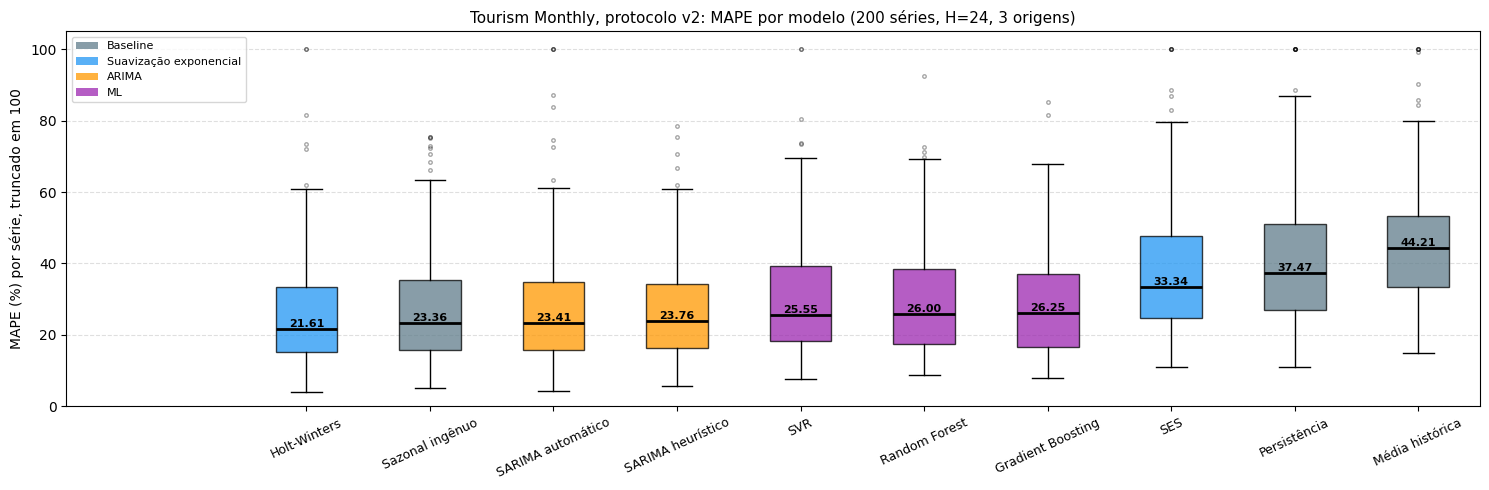

In [7]:
ordem_m = [next(k for k, v in NOMES.items() if v == n) for n in tab.index]
cores = {'Baseline': '#607D8B', 'Suavização exponencial': '#2196F3', 'ARIMA': '#FF9800', 'ML': '#9C27B0'}
dados = [bs[bs.model == m]['mape'].dropna() for m in ordem_m]
fig, ax = plt.subplots(figsize=(15, 5))
bp = ax.boxplot([d.clip(upper=100) for d in dados], patch_artist=True, medianprops=dict(color='black', linewidth=2),
                flierprops=dict(marker='o', markersize=2.5, alpha=0.35))
for patch, m in zip(bp['boxes'], ordem_m):
    patch.set_facecolor(cores[pv.FAMILIA[m]]); patch.set_alpha(0.75)
for i, d in enumerate(dados):
    ax.text(i + 1, d.median(), f'{d.median():.2f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(range(1, len(ordem_m) + 1)); ax.set_xticklabels([NOMES[m] for m in ordem_m], rotation=25, fontsize=9)
for f_, c in cores.items():
    ax.bar(0, 0, color=c, alpha=0.75, label=f_)
ax.legend(fontsize=8); ax.grid(axis='y', linestyle='--', alpha=0.4); ax.set_ylabel('MAPE (%) por série, truncado em 100')
ax.set_title('Tourism Monthly, protocolo v2: MAPE por modelo (200 séries, H=24, 3 origens)', fontsize=11)
plt.tight_layout(); plt.savefig(DIR / 'fig_v2_tm_boxplot_mape.png', dpi=150, bbox_inches='tight'); plt.show()